# 🧪 LAB: Manual MLPs for Classification and Regression

In this lab, you will use `PyTorch` to implement manually a multi-layer perceptron (MLP) for three different tasks: binary classification, multi-class classification and regression. 

## General instructions to complete in ALL three tasks:

1. ***IMPLEMENTATION***:
   
Implement a separate class for each task:

  - `BinaryMLP` for the binary classification task  
  - `MultiClassMLP` for the multi-class classification task  
  - `RegressionMLP` for the regression task

   Each class must include the following methods:

  - `__init__` for initializing 1 or 2 hidden layers. (*Help*: having a second hidden layer only means the need of having a extra set of weights and intercept). 
  - `forward` to transfer information from the input to the output layer. (*Help*: make sure that information passes through a second hidden layer if there is one).
  - `cost` computing the cost.
  - `fit` for training, using the gradients to manually update the parameters of the model. **Use stochastic gradient descent to update your weights**. *N.B.* You may probably reuse much of the code we used in this week tutorial already. 
  - `predict` to convert the information at the output layer into the required output.

2. ***DATA PREPARATION***

For each task, you will be provided with a toy dataset. For each dataset:

  - Split into training and holdout sets (use an 80/20 split)
  - Standardize the features properly, avoiding data leakage
  - Convert all data into `PyTorch` Tensors for compatibility

3. ***MODEL TRAINING AND EVALUATION***

Instantiate the model for each task and train it under different hyperparameter configurations. In each case, record the performance on **both** the training and holdout sets using the appropriate metric for the task (accuracy, MSE, etc.). You should explore the following configurations:

  - One hidden layer, varying the number of hidden units (use ReLU as their activation function)
  - Same number of hidden units across one or two hidden layers (use ReLU as their activation function)
  - Repeat the above setups using Tanh activation instead of ReLU

Present your results in a compact way (e.g., a summary table, a data frame etc).

**NOTE**: When training your model, use a fixed learning rate of your choice (e.g., 0.01 is a reasonable starting point) and a reasonably large number of  epochs (e.g., 100–200) based on how training and holdout performance evolve.

4. ***REFLECTION AND DISCUSSION***

Reflect on the impact of the different hyperparameter settings:

- How does the number of hidden units affect performance?
- What changes when using two layers instead of one?
- How does the activation function (ReLU vs. Tanh) influence results?

Please elaborate your answers.

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

**Ideally, each group member should be responsible for one of the separate tasks.** BUT, everyone should help each other along the way, both reviewing and refining results and discussion.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


In [1]:
NAMEs = "Laine Goldmacher, Max Magrill, Ashley Qin"

## 1. Pre-implementation Group Discussion (15 points)

Discuss and agree on:

- What cost function should be used for each of the below task.
- What changes are needed in the output layer for each of these tasks. In particular, consider the number of units and the activation function.
- Why it is important to standardize the data before training each model.
- How you could detect overfitting when training your models.

1. Binary Cross-Entropy (aka log loss), Categorical Cross-Entropy, and Mean Squared Error (MSE) should be used for Binary Classification, Multi-Class Classification, and Regression respectively. 
   1. Binary Cross-Entropy (BCE) measures the difference between predicted probabilities and their actual binary labels (0 or 1).
   2. Categorical Cross-Entropy measures how well the predicted probability distribution matches the true class, penalizing low probabilities assigned to the correct class.
   3. MSE measures the average squared difference between predicted and actual continuous values, penalizing larger errors more heavily.
2. For Binary Classification, there should be one output unit using a sigmoid activation function, producing a probability between 0 and 1. Predictions are classified using a threshold, typically 0.5. For Multi-Class Classification, there should also be as many output units as classes we have using a softmax activation function, producing probabilities that sum to 1. The predicted class is the one with the highest probability. Finally, for Regression, there should still be one output unit with no activation, allowing predictions to take any real value.
3. It is important to standardize the data before training each model because standardization ensures that features are on comparable scales, preventing features with larger numerical values from disproportionately influencing gradient updates. This improves the stability and convergence speed of stochastic gradient descent, making training more efficient. It should be fitted on the data before training each model to avoid data leakage; the scaler is fitted on the training data and then applied to both training and holdout sets.
4. Overfitting occurs when a model learns the patterns specific to training data rather than generalizable relationships. We can detect it by comparing training and holdout performance across epochs. If training loss continues decreasing while holdout loss increases, or if training accuracy improves while holdout accuracy stagnates or decreases, this is a sign of overfitting. A large difference in performance between the training and holdout sets is another indicator.

## 2. Binary Classification (25 points)

Use the dataset below to complete points 1 to 4 in the general instructions for this task.

Use as many cells as needed.

In [2]:
from sklearn.datasets import make_moons

X, y = make_moons(n_samples=1000, noise=0.2, random_state=42)

In [3]:
# USE AS MANY CELLS AS NEEDED

## 2. Multi-Class Classification (25 points)

Use the dataset below to complete points 1 to 4 in the general instructions for this task.

Use as many cells as needed.

---
**NOTE**: This will likely be the most challenging exercise. To help you, here are some pointers:

 - The **output (last) layer** should have as many units as there are classes in your data.  

 - The **activation function of the output layer must be softmax**, not sigmoid. Softmax ensures that all output values are between 0 and 1 and sum to 1, so they can be interpreted as probabilities across the different classes. (*Help*: you may want to look into `torch.nn.functional` to find its implementation...)

 - For a multi-class problem, your target variable `y` should be **one-hot encoded**. For example:  
   - Label = 0 → [1, 0, 0]  
   - Label = 1 → [0, 1, 0]  
   - Label = 2 → [0, 0, 1]  
   You can easily achieve this with `OneHotEncoder` from `sklearn.preprocessing`.  

 - The **predicted class** corresponds to the unit with the highest probability.  
   Example:  
   - `[0.1, 0.3, 0.6] → class 2`  
   - `[0.6, 0.2, 0.2] → class 0`  

 - For this exercise, you need to **implement the categorical cross-entropy loss** (an extension of binary cross-entropy to multiple classes). It is defined as:  

   $$\sum_{c=1}^{l} y_{o,c}\,\log(p_{o,c}),$$

   where $l$ is the number of classes, $y_{o,c}$ is the one-hot encoded label for observation $o$, and $p_{o,c}$ is the predicted probability for class $c$ (after applying softmax). The log is the natural logarithm.

---

In [4]:
from sklearn.datasets import make_classification

X, y = make_classification(n_samples=1000, n_classes=3, 
                           n_clusters_per_class=1, 
                           n_features=2, n_informative=2, n_redundant=0, random_state=1234, flip_y=0.15)

In [5]:
# USE AS MANY CELLS AS NEEDED

## 3: Regression Task (25 points)

Use the dataset below to complete points 1 to 4 in the general instructions for this task.

Use as many cells as needed.

In [6]:
# importing packages
import numpy as np
import matplotlib.pyplot as plt
import torch
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

In [7]:
# importing data
from sklearn.datasets import make_regression
X, y = make_regression(n_samples=1000, n_features=2, n_informative=2, random_state=1234, noise=75)

In [8]:
# implementation
class RegressionMLP(object):
    
    def __init__(self, 
                 input_dim=2, 
                 hidden_dim=10, 
                 num_layers=1,
                 activation='relu'):

        self.activation = activation

        dims = [input_dim] + [hidden_dim] * num_layers + [1]

        self.weights = []
        self.biases = []

        for i in range(len(dims) - 1):
            W = torch.randn(dims[i], dims[i+1]) * np.sqrt(2 / dims[i])
            b = torch.zeros(1, dims[i+1])

            self.weights.append(W.requires_grad_())
            self.biases.append(b.requires_grad_())
    
    def forward(self, X):
        a = X 

        for W, b in zip(self.weights[:-1], self.biases[:-1]):
            z = a @ W + b
        
            if self.activation == "relu":
                a = torch.relu(z)
            elif self.activation == "tanh":
                a = torch.tanh(z)

        output = a @ self.weights[-1] + self.biases[-1]
        return output

    def cost(self, y_pred, y_true):
        return torch.mean((y_pred - y_true) ** 2)
    
    def fit(self, X, y, lr=0.01, epochs=150):
        self.loss_history = []

        for epoch in range(epochs):
            indices = torch.randperm(len(X))

            for i in indices:
                xi = X[i:i+1]
                yi = y[i:i+1]

                pred = self.forward(xi)
                loss = self.cost(pred, yi)

                loss.backward()

                with torch.no_grad():
                    for W, b in zip(self.weights, self.biases):
                        W -= lr * W.grad
                        b -= lr * b.grad

                        W.grad.zero_()
                        b.grad.zero_()

            with torch.no_grad():
                epoch_loss = self.cost(self.forward(X), y).item()
                self.loss_history.append(epoch_loss)

        return self
        
    def predict(self, X):
        with torch.no_grad():
            return self.forward(X)


In [9]:
# data preparation (train/test split, standardization, PyTorch conversion)
X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, y, test_size=0.2, random_state=1234
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_holdout = scaler.transform(X_holdout)

y_scaler = StandardScaler()
y_train = y_scaler.fit_transform(y_train.reshape(-1, 1))
y_holdout = y_scaler.transform(y_holdout.reshape(-1, 1))

X_train = torch.tensor(X_train, dtype=torch.float32)
X_holdout = torch.tensor(X_holdout, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32)
y_holdout = torch.tensor(y_holdout, dtype=torch.float32)

In [10]:
# training and evaluation

configs = [
    (1, 5, "relu"),
    (1, 10, "relu"),
    (2, 10, "relu"),
    (1, 5, "tanh"),
    (1, 10, "tanh"),
    (2, 10, "tanh")]

results = []
models = {}

for layers, units, activation in configs:
    torch.manual_seed(1234)

    model = RegressionMLP(
        input_dim=2,
        hidden_dim=units,
        num_layers=layers,
        activation=activation
    )

    model.fit(X_train, y_train, lr=0.01, epochs=150)

    train_pred = y_scaler.inverse_transform(model.predict(X_train).numpy())
    holdout_pred = y_scaler.inverse_transform(model.predict(X_holdout).numpy())

    train_mse = mean_squared_error(y_scaler.inverse_transform(y_train.numpy()), train_pred)
    holdout_mse = mean_squared_error(y_scaler.inverse_transform(y_holdout.numpy()), holdout_pred)
    
    results.append({
        "Layers": layers,
        "Hidden Units": units,
        "Activation": activation,
        "Train MSE": train_mse,
        "Holdout MSE": holdout_mse
    })

    models[(layers, units, activation)] = model

results_df = pd.DataFrame(results)
results_df.round(2)

,Layers,Hidden Units,Activation,Train MSE,Holdout MSE
0,1,5,relu,5535.83,5502.25
1,1,10,relu,5529.49,5637.13
2,2,10,relu,5449.96,5561.79
3,1,5,tanh,5515.64,5266.51
4,1,10,tanh,5722.61,5706.75
5,2,10,tanh,5434.20,5738.90


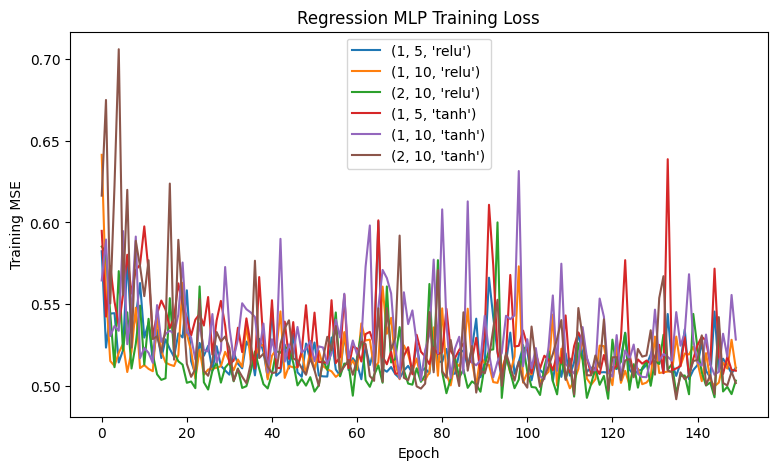

In [11]:
plt.figure(figsize=(9, 5))

for config, model in models.items():
    plt.plot(model.loss_history, label=str(config))

plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("Regression MLP Training Loss")
plt.legend()
plt.show()

Regression reflection and discussion

1. How does the number of hidden units affect performance?
- Increasing the number of hidden units from 5 to 10 did not consistently improve performance. For ReLU, training MSE decreased slightly from 5535.83 to 5529.49, while holdout MSE increased from 5502.25 to 5637.13. For Tanh, both training and holdout MSE increased, suggesting that additional hidden units did not improve the model's ability to learn or generalize. Since the dataset has a relatively simple underlying linear relationship, increasing model complexity may not provide substantial benefits.
2. What changes when using two layers instead of one?
- Adding a second hidden layer improved training performance for both activation functions when compared to the corresponding one-layer, 10-unit models. ReLU training MSE decreased from 5529.49 to 5449.96, while Tanh training MSE decreased from 5722.61 to 5434.20. However, holdout performance improved slightly for ReLU but worsened for Tanh. This suggests that deeper networks can fit the training data more effectively, but increased complexity does not necessarily improve generalization.
3. How does the activation function (ReLU vs. Tanh) influence results?
- The impact of activation function varied across architectures. Tanh achieved the lowest overall holdout MSE (5266.51) with 1 hidden layer and 5 units, outperforming ReLU with the same architecture. However, ReLU performed better with 1 hidden layer and 10 units, as well as with 2 hidden layers and 10 units. This suggests that neither activation function consistently outperformed the other. Tanh can be effective at modeling smooth relationships, while ReLU may train more efficiently because it avoids saturation for positive inputs.

## 4. Discussion (5 points)

You created a separate class for each task and likely repeated much of the same code across implementations.

Discuss within your group how could you have leveraged inheritance to make your code more reusable and avoid duplication. Provide examples. Be specific.

YOUR TEXT HERE

## 5. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE